# Climate Comfort Index · Model selection, final fit and promotion

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Pipeline stages 3-8 · shortlist, select features, choose, test once, deploy*

This notebook takes the tuned CCI experiments through the rest of the pipeline: it shortlists the best algorithms, selects feature families for each, chooses one champion, refits it on all development data, scores it **once** on the test split and promotes it to `models/comfort_climate/production/` for the FastAPI service. It is the **only notebook that reads the test split**.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

| Stage | What happens | Features | Data | Section |
|:-:|:--|:--|:--|:-:|
| 1–2 | Baselines and hyperparameter tuning (done in the experiment notebooks) | All 105 | Walk-forward CV | 1 |
| 3 | Shortlist the best tuned algorithms | All | – | 2 |
| 4 | Feature selection with the settings fixed, then a short re-tune | Per model | Walk-forward CV | 3 |
| 5 | Select the champion | Champion's own | CV scores | 4 |
| 6 | Final fit | Champion's own | All development data (2016–2024) | 5 |
| 7 | Test once | Champion's own | Test (2025) | 6 |
| 8 | Deploy, with a drift reference for monitoring | Champion's own | Production | 7 |

**Two searches, not one.** Each experiment notebook tuned its algorithm's settings on all
features, so every algorithm competes after tuning. Feature selection is spent only on the
shortlist, with the settings fixed, followed by a short re-tune because good settings depend on
the features.

**Why the scores are comparable.** Every experiment used the same four walk-forward folds
(validating on 2021, 2022, 2023 and 2024), so the saved cross-validated scores are compared
directly, without refitting anything.

**Why the test split is still honest.** Every decision (shortlist, features, settings, champion)
is made with cross-validation before the test split is read. It is scored once, in section 6.

> **Runtime.** Feature selection fits `(FEATURE_TRIALS + RETUNE_TRIALS) x folds x targets` models
> per shortlisted algorithm. Lower the trial counts for a quicker run.

---
## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"
SHORTLIST_SIZE = 3    # stage 3: algorithms kept for feature selection
FEATURE_TRIALS = 20   # stage 4: Optuna trials over the feature-family switches
RETUNE_TRIALS = 10    # stage 4: short re-tune of the settings on the chosen features
VERBOSE = 1           # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit

task = wx.load_task(TASK)
print(f"{task.target_name} | metric: {task.metric} | targets: {task.target_columns}")

Climate Comfort Index | metric: mae | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Tuned experiments (stages 1-2)

Each experiment notebook saved its tuned model, its cross-validated scores and its specification.
Bundles built on an older feature set are excluded; rerun their notebooks to include them. The
ranking reads the saved scores, including the baselines' scores on the same folds.

Excluded (stale or empty): none


,algorithm,models_found,horizons
experiment,,,
cci_dummy_mean,Dummy Regressor,3,"[1, 2, 3]"
cci_mlp,MLP Regressor,3,"[1, 2, 3]"
cci_polynomial_regression,Polynomial Ridge Regression,3,"[1, 2, 3]"
cci_random_forest,Random Forest Regressor,3,"[1, 2, 3]"
cci_xgboost,XGBoost Regressor,3,"[1, 2, 3]"


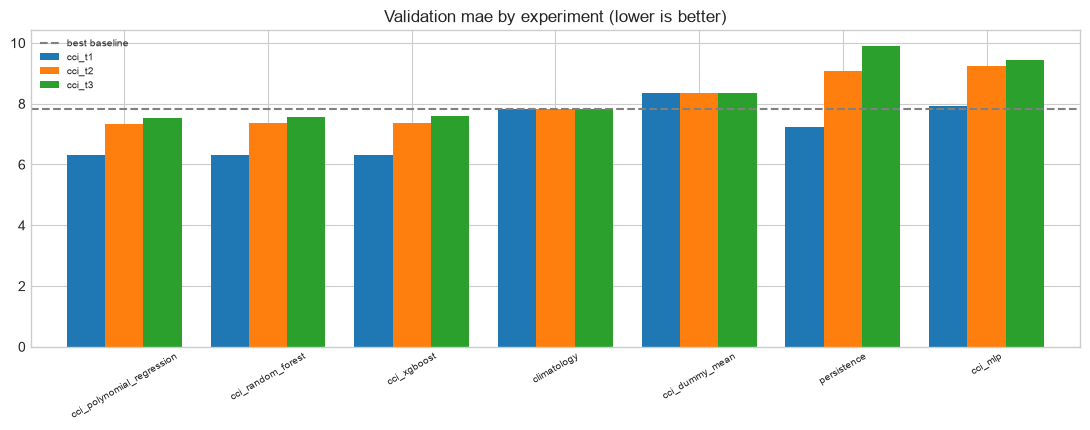

target,cci_t1,cci_t2,cci_t3,score,is_baseline
experiment,,,,,
cci_polynomial_regression,6.312,7.336,7.536,7.062,False
cci_random_forest,6.309,7.355,7.559,7.074,False
cci_xgboost,6.322,7.359,7.586,7.089,False
climatology,7.831,7.831,7.830,7.831,True
cci_dummy_mean,8.340,8.345,8.347,8.344,False
persistence,7.240,9.069,9.917,8.742,True
cci_mlp,7.932,9.253,9.452,8.879,False


In [2]:
bundles = wx.discover_bundles(task)
contract = wx.check_feature_contract(bundles, task)
usable = contract["matches_current"] & contract["has_models"]
COMPARED = contract.index[usable].tolist()
if not COMPARED:
    raise RuntimeError("No bundle matches the current feature set. Rerun the experiment notebooks.")
print(f"Excluded (stale or empty): {contract.index[~usable].tolist() or 'none'}")
display(wx.bundle_inventory(bundles))

ranking = wx.rank_tuned(task, {name: bundles[name] for name in COMPARED})
wx.plot_ranking(task, ranking, f"{task.name}-tuned-ranking")
plt.show()
ranking

---
## 2. Shortlist (stage 3)

The best tuned algorithms go forward. Baselines and null models (the dummies) are listed but never
shortlisted: they are the floor, not candidates.

In [3]:
SHORTLIST, shortlist_table = wx.shortlist(ranking, bundles, size=SHORTLIST_SIZE)
print(f"Shortlisted for feature selection: {SHORTLIST}")
shortlist_table

Shortlisted for feature selection: ['cci_polynomial_regression', 'cci_random_forest', 'cci_xgboost']


,screening_score,status
experiment,,
cci_polynomial_regression,7.062,shortlisted
cci_random_forest,7.074,shortlisted
cci_xgboost,7.089,shortlisted
cci_dummy_mean,8.344,excluded: null model
cci_mlp,8.879,not shortlisted


---
## 3. Feature selection (stage 4)

Each shortlisted experiment is restored with its tuned settings. Optuna then switches each feature
family on or off (today's persistence column is always kept) with the settings fixed, scoring
every combination with walk-forward CV. The settings are then re-tuned briefly on the chosen
features and kept only if they improve the score. Each horizon is handled separately.

The table for each experiment lists the mean and spread across folds, the features kept, the
families dropped and whether the re-tune helped.

In [4]:
refined = {}
for name in SHORTLIST:
    refined[name] = wx.Experiment.from_bundle(task, bundles[name], verbose=VERBOSE)
    print(f"\n=== {name} ===")
    display(refined[name].select_features(n_trials=FEATURE_TRIALS, retune_trials=RETUNE_TRIALS))

print("Walk-forward folds:")
refined[SHORTLIST[0]].folds_table()

[cci_polynomial_regression] loaded 3,255 development rows; 4 walk-forward folds; 105 features; metric mae (lower is better)

=== cci_polynomial_regression ===
[cci_polynomial_regression] selecting features for cci_t1: 20 trials


/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-09-19 13:14:29,791] A new study created in memory with name: cci_polynomial_regression_cci_t1_features
[I 2026-09-19 13:14:29,881] Trial 0 finished with value: 6.312149939493697 and parameters: {'family__same_day_observations': False, 'family__same_day_indices': False, 'family__lags': False, 'family__rolling_statistics': False, 'family__rolling_precipitation': True, 'family__rolling_gusts': False, 'family__deltas': True, 'family__seasonal': False}. Best is trial 0 with value: 6.312149939493697.
[I 2026-09-19 13:14:29,907] Trial 1 finished with value: 6.312149939493697 and parameters: {'family__same_day_observations': False, 'family__same_day_indices'

[cci_polynomial_regression] re-tuning cci_t1 on 11 features: 10 trials


[I 2026-09-19 13:14:30,420] A new study created in memory with name: cci_polynomial_regression_cci_t1_retune
[I 2026-09-19 13:14:30,444] Trial 0 finished with value: 6.513389892991492 and parameters: {'degree': 2, 'interaction_only': False, 'alpha': 0.4356821271417881}. Best is trial 0 with value: 6.513389892991492.
[I 2026-09-19 13:14:30,460] Trial 1 finished with value: 7.344664722996287 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 3873.9746708167268}. Best is trial 0 with value: 6.513389892991492.
[I 2026-09-19 13:14:30,479] Trial 2 finished with value: 6.460695210306639 and parameters: {'degree': 2, 'interaction_only': True, 'alpha': 26.65811983933415}. Best is trial 2 with value: 6.460695210306639.
[I 2026-09-19 13:14:30,494] Trial 3 finished with value: 6.423885935829049 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 103.13141058928771}. Best is trial 3 with value: 6.423885935829049.
[I 2026-09-19 13:14:30,510] Trial 4 finished with value: 

[cci_polynomial_regression] cci_t1: mean mae = 6.5135 with 11 features (re-tuned: False)
[cci_polynomial_regression] selecting features for cci_t2: 20 trials


...

[I 2026-09-19 13:21:31,274] A new study created in memory with name: cci_xgboost_cci_t3_retune
[I 2026-09-19 13:21:32,357] Trial 0 finished with value: 7.786348117622223 and parameters: {'n_estimators': 200, 'learning_rate': 0.015958100115314407, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578}. Best is trial 0 with value: 7.786348117622223.
[I 2026-09-19 13:21:38,241] Trial 1 finished with value: 8.581665022110007 and parameters: {'n_estimators': 900, 'learning_rate': 0.11876838817573318, 'max_depth': 4, 'min_child_weight': 30, 'subsample': 0.9817065761225814, 'colsample_bytree': 0.4016165055839879, 'reg_lambda': 6.932871909467083, 'reg_alpha': 0.5357023521579158}. Best is trial 0 with value: 7.786348117622223.
[I 2026-09-19 13:21:43,976] Trial 2 finished with value: 8.293686170833453 and parameters: {'n_estimators': 400, 'learning_rate': 0.06129236268182

[cci_xgboost] cci_t3: mean mae = 7.8135 with 11 features (re-tuned: False)


,cv_mean,cv_std,fold_scores,n_features,dropped_families,retuned,best_params
target,,,,,,,
cci_t1,6.519,0.230,"[6.3149, 6.8053, 6.3525, 6.6023]",11,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 700, 'learning_rate': 0.00668..."
cci_t2,7.584,0.274,"[7.4672, 7.9919, 7.4764, 7.4003]",11,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 650, 'learning_rate': 0.00543..."
cci_t3,7.814,0.367,"[7.7345, 8.3488, 7.5213, 7.6494]",11,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 300, 'learning_rate': 0.00909..."


Walk-forward folds:


,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2016-01-31,2020-12-26,2020-12-30,2021-12-29,1792,365
2,2016-01-31,2021-12-26,2021-12-30,2022-12-29,2157,365
3,2016-01-31,2022-12-26,2022-12-30,2023-12-29,2522,365
4,2016-01-31,2023-12-26,2023-12-30,2024-12-28,2887,365


---
## 4. Select the champion (stage 5)

The rule is **lowest mean MAE over the walk-forward folds, averaged across the three horizons**, fixed before the results were seen.

The average over horizons is used because all three models ship together behind one endpoint: a
pipeline that wins at *t*+1 but loses badly at *t*+3 would be the wrong choice.

`typical_fold_std` shows how much a score moves from one year to the next. If the champion's
margin over the runner-up is smaller than that, the two are not clearly separated, and simplicity,
cost or interpretability can decide between them.

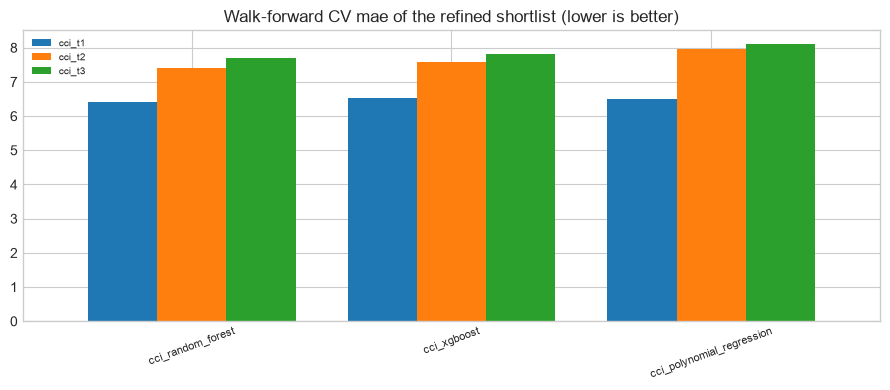

Champion : cci_random_forest (score 7.1638)
Runner-up: cci_xgboost (margin 0.1416, typical fold spread 0.2870)


target,cci_t1,cci_t2,cci_t3,score,typical_fold_std,mean_features
experiment,,,,,,
cci_random_forest,6.406,7.395,7.690,7.164,0.287,41.667
cci_xgboost,6.519,7.584,7.814,7.305,0.290,11.000
cci_polynomial_regression,6.514,7.955,8.099,7.523,0.367,11.000


,cv_mean,cv_std,fold_scores,n_features,dropped_families,retuned,best_params
target,,,,,,,
cci_t1,6.406,0.168,"[6.3729, 6.6241, 6.2155, 6.4095]",47,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 400, 'max_depth': 16, 'min_sa..."
cci_t2,7.395,0.317,"[7.3641, 7.817, 7.3534, 7.0472]",61,"[same_day_observations, lags, deltas]",False,"{'n_estimators': 600, 'max_depth': 6, 'min_sam..."
cci_t3,7.690,0.375,"[7.5747, 8.2445, 7.415, 7.5272]",17,"[same_day_indices, lags, rolling_statistics, d...",False,"{'n_estimators': 150, 'max_depth': 10, 'min_sa..."


In [5]:
refinement = wx.compare_refined(task, refined)
champion = wx.select_champion(refinement)
CHAMPION = champion["champion"]

wx.plot_cv_comparison(task, refinement, f"{task.name}-feature-selection")
plt.show()
print(f"Champion : {CHAMPION} (score {champion['score']:.4f})")
print(f"Runner-up: {champion['runner_up']} (margin {champion['margin']:.4f}, "
      f"typical fold spread {champion['typical_fold_std']:.4f})")
for message in champion["warnings"]:
    print(f"WARNING: {message}")
display(refinement)
refined[CHAMPION].cv_summary

---
## 5. Final fit (stage 6)

The champion's settings and features are refitted on **all development data** (2016–2024). Every
decision was made with cross-validation, so the most recent year can now be used for training.

In [6]:
final_models = refined[CHAMPION].refit_final()
FINAL_MODELS = {wx.horizon_from_name(t): m for t, m in final_models.items()}
FEATURES = {wx.horizon_from_name(t): c for t, c in refined[CHAMPION].best_columns.items()}
{h: len(c) for h, c in FEATURES.items()}   # number of features used per horizon

[cci_random_forest] final fit cci_t1: 3,255 rows, 47 features
[cci_random_forest] final fit cci_t2: 3,255 rows, 61 features
[cci_random_forest] final fit cci_t3: 3,255 rows, 17 features


{1: 47, 2: 61, 3: 17}

---
## 6. Single test evaluation (stage 7)

The test split (2025) is loaded and scored **once**, for the champion and for the baselines (also
fitted on all development data). Nothing after this point changes any decision.

Expect the test score to be a little worse than the CV score: that is the selection optimism being
paid back. A large gap belongs in the limitations section of the report.

Selection optimism for cci_random_forest (mae):


,walk_forward_cv,test,test_minus_cv
target,,,
cci_t1,6.406,6.793,0.387
cci_t2,7.395,7.737,0.341
cci_t3,7.690,8.162,0.472


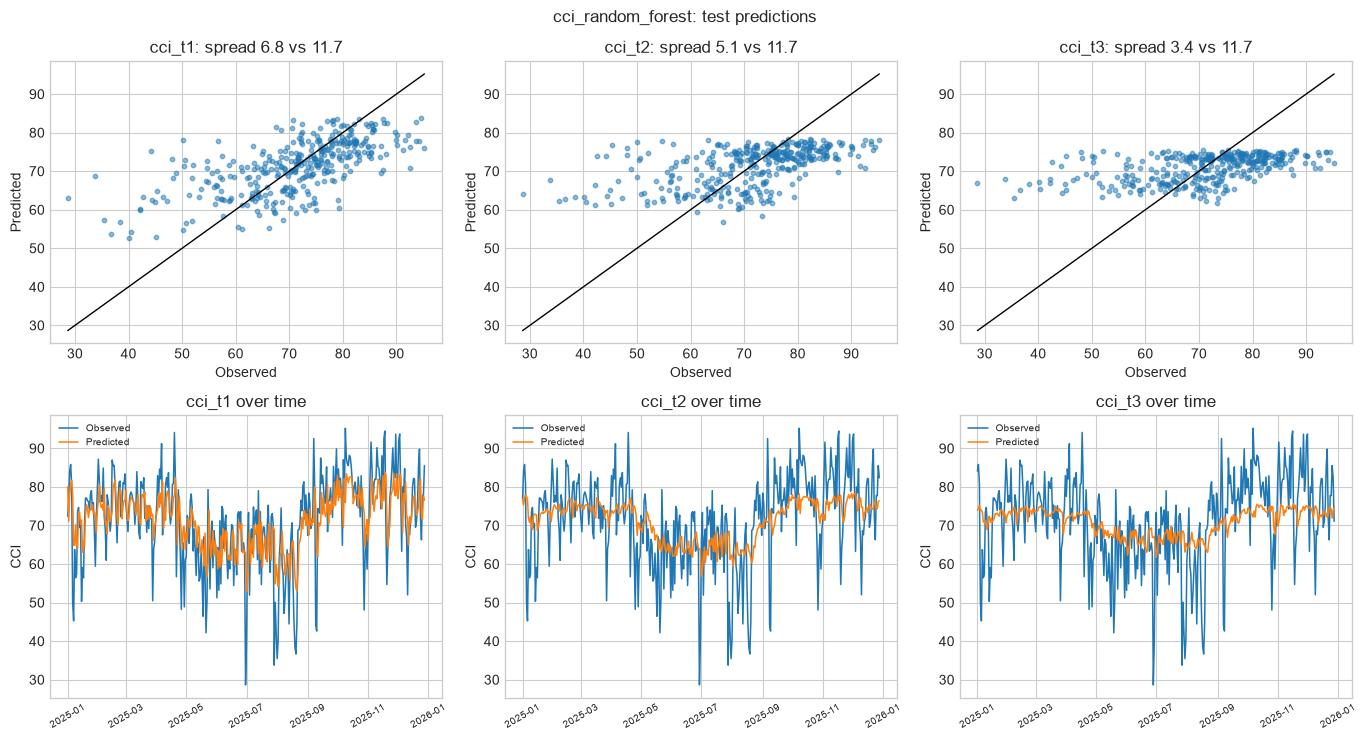

is_baseline    mae   rmse     r2  pred_std
target experiment                                                   
cci_t1 cci_random_forest        False  6.793  8.985  0.413     6.848
cci_t2 cci_random_forest        False  7.737 10.083  0.263     5.108
cci_t3 cci_random_forest        False  8.162 10.554  0.192     3.436
cci_t1 persistence               True  7.722 10.088  0.260    11.721
       climatology               True  8.142 10.669  0.172     3.875
cci_t2 persistence               True  9.582 12.601 -0.152    11.721
       climatology               True  8.156 10.673  0.174     3.875
cci_t3 persistence               True 10.070 13.384 -0.300    11.721
       climatology               True  8.159 10.674  0.173     3.880

In [7]:
X, y = wx.load_splits(task, ("train", "test"))
# Classification metrics are averaged over the classes seen in training.
LABELS = sorted(y["train"][task.target_columns[0]].unique()) if task.is_classification else None

test_rows = (wx.score_models(task, CHAMPION, FINAL_MODELS, FEATURES, X, y, "test", LABELS)
             + wx.score_baselines(task, X, y, "test", LABELS))
test_scores = pd.DataFrame(test_rows).drop(columns=["split"]).set_index(["target", "experiment"])

optimism = pd.DataFrame({
    "walk_forward_cv": refined[CHAMPION].cv_summary["cv_mean"],
    "test": test_scores.xs(CHAMPION, level="experiment")[task.metric],
})
optimism["test_minus_cv"] = optimism["test"] - optimism["walk_forward_cv"]
print(f"Selection optimism for {CHAMPION} ({task.metric}):")
display(optimism)

wx.plot_test_predictions(task, FINAL_MODELS, FEATURES, X, y,
                         f"{CHAMPION}: test predictions", f"{task.name}-test")
plt.show()
test_scores

---
## 7. Promote to production (stage 8)

The champion is written to `models/comfort_climate/production/`, replacing whatever was there:

| File | Contents |
|:--|:--|
| `<champion>_h<horizon>.joblib` | The final models, fitted on all development data |
| `metadata.json` | The `/model-metadata` document: CV and test metrics, features and importance per horizon |
| `manifest.json` | Model files and **each model's own feature list** (the API selects these columns) |
| `drift_reference.json` | The training distribution of every feature used, for drift monitoring |
| `promotion.json` | The audit record: ranking, shortlist, feature selection, test and warnings |

> The FastAPI service loads from `production/` (copied with `make artefacts`) and compares recently
> served feature rows with `drift_reference.json` at `/monitoring/drift`.

In [8]:
record = wx.promotion_record(task, champion, ranking, shortlist_table, refinement,
                             test_scores, refined[CHAMPION])
destination = wx.promote_champion(task, refined[CHAMPION], test_scores, record)

print(f"Promoted {CHAMPION} -> {destination.relative_to(task.root)}")
sorted(path.name for path in destination.iterdir())

Promoted cci_random_forest -> models/comfort_climate/production


['cci_random_forest_h1.joblib',
 'cci_random_forest_h2.joblib',
 'cci_random_forest_h3.joblib',
 'drift_reference.json',
 'manifest.json',
 'metadata.json',
 'promotion.json']

---
## 8. Conclusions

Points to carry into the report:

- **The ranking after tuning.** Which algorithms were shortlisted, and by what margin.
- **What feature selection changed.** Which families were dropped for which horizon, and whether
  the re-tune helped; this is the quantitative answer to "which features matter".
- **The champion, and how clear the win was.** Compare the margin over the runner-up with the
  typical fold spread.
- **Quote the test score, not the CV score,** and report the optimism between them.
- **Against the baselines on test.** Improvement over the naive forecasts is more informative than
  any absolute number.
- **Monitoring.** The production bundle carries a drift reference; the API reports when served
  data leaves the training range, which is the trigger for retraining.

> Rerun this notebook whenever an experiment notebook is rerun, so the promotion record never
> refers to results that have since changed.